# Munich rents: spatial effects with `bmrf` and `bspatial`

Munich publishes a *Mietspiegel*, a rent index. German tenancy law allows a
landlord to raise rent toward the local reference level and no further, so the
fitted value for an apartment is the figure both parties refer to.

Location enters the model through the district an apartment is in. A district
is a label, and a label can be represented in several ways: as 336 unrelated
categories, as a set of neighbouring districts on a map, or as a position on a
smooth surface over the city. Each representation is a different assumption
about how location acts. This study fits all three on the same data and the
same folds, compares them by paired cross-validated risk, and reads the fitted
district maps.


:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | the local reference rent that German tenancy law lets a landlord charge |
| **Observed response** | `rentsqm`, net rent per square metre |
| **Estimand** | the conditional mean rent per m² given apartment characteristics and district |
| **Units** | euros per square metre per month |
| **Sampling unit** | one apartment; 3082 across 336 districts |
| **Dependence** | apartments cluster in districts, and districts are spatially adjacent. This is modelled explicitly by `bmrf`, a Markov random field term with one effect per district, each shrunk toward the effects of its neighbouring districts |
| **Split / resampling unit** | the apartment, which means a district's own apartments appear on both sides of a fold. A district-level split would answer a different question |
| **Tuning** | `mstop` by cross-validated risk |
| **Uncertainty** | not resampled here; the fitted surface is the deliverable |
| **Claim type** | descriptive — a reference level, which is what the law asks for, not a causal effect of any feature on rent |
:::


## The data

`munich_rent` holds the 1999 survey: 3082 apartments, with net rent per square
metre as the response, and floor area, construction year, three fittings
indicators and a location grade as predictors. Each apartment carries the code
of one of 336 city districts.

The survey covers rent-controlled tenancies in one city in one year. It does
not describe owner-occupied housing, new lettings at market rates, or Munich
after 1999.


In [1]:
import warnings

import numpy as np
import polars as pl

import mboostrs as mb

rent = mb.datasets.munich_rent()
adjacency = mb.datasets.munich_rent_adjacency()
centroids = mb.datasets.munich_rent_districts()

print(f"{rent.height} apartments in {rent['district'].n_unique()} districts")
print(f"rent per m2: mean {rent['rentsqm'].mean():.2f}, "
      f"sd {rent['rentsqm'].std():.2f}, "
      f"range [{rent['rentsqm'].min():.2f}, {rent['rentsqm'].max():.2f}]")

per_district = rent.group_by("district").len()["len"].to_numpy()
print(f"\napartments per district: min {per_district.min()}, "
      f"median {np.median(per_district):.0f}, max {per_district.max()}")
print(f"districts with a single apartment surveyed: {(per_district == 1).sum()}")

3082 apartments in 336 districts
rent per m2: mean 7.11, sd 2.44, range [0.42, 17.72]

apartments per district: min 1, median 6, max 53
districts with a single apartment surveyed: 46


46 of the 336 districts contain exactly one surveyed apartment, and the median
district contains six. Estimating 336 separate district effects therefore uses
few observations per effect.


## Neighbourhood matrix for `bmrf`

`bmrf` requires the neighbourhood structure as a graph Laplacian: the diagonal
holds each district's neighbour count, an off-diagonal entry is `-1` for a pair
sharing a border, and every row sums to zero. With that form, $\beta^\top K
\beta$ equals $\sum_{i \sim j} (\beta_i - \beta_j)^2$ summed over bordering
pairs, so the penalty measures disagreement between neighbouring districts.

The bundled adjacency lists the bordering pairs, derived from the district
boundary polygons. Two districts count as neighbours when their outlines share
at least two vertices, so a shared edge qualifies and a single touching corner
does not.


In [2]:
codes = sorted(rent["district"].unique().to_list())
position = {d: i for i, d in enumerate(codes)}
n_districts = len(codes)

K = np.zeros((n_districts, n_districts))
for a, b in zip(adjacency["a"], adjacency["b"]):
    i, j = position[a], position[b]
    K[i, j] = K[j, i] = -1.0
    K[i, i] += 1.0
    K[j, j] += 1.0

degree = np.diag(K)
print(f"{adjacency.height} bordering pairs")
print(f"neighbours per district: min {degree.min():.0f}, "
      f"median {np.median(degree):.0f}, max {degree.max():.0f}")
print(f"districts with no neighbour: {(degree == 0).sum()}")

eigenvalues = np.linalg.eigvalsh(K)
print(f"\nzero eigenvalues of K: {(np.abs(eigenvalues) < 1e-8).sum()}")

685 bordering pairs
neighbours per district: min 0, median 4, max 9
districts with no neighbour: 1

zero eigenvalues of K: 3


K has three zero eigenvalues. The null space of a penalty is the set of
coefficient vectors it leaves unpenalized; for a graph Laplacian these are the
vectors that are constant within each connected component of the graph, so the
null space has one dimension per component. The district graph therefore falls
into three pieces: a main component of 333 districts, district 121, which
borders nothing under the shared-edge rule, and the pair 1212 and 1213, which
border only each other.

The penalty leaves the components free to move relative to each other, because
no border connects them. A district with no neighbours receives no smoothing.
District 121 is in that position, with one surveyed apartment, so its effect is
estimated from that apartment under any of the specifications below.

`bmrf(center=True)` projects the design onto the directions the penalty
constrains, so the unpenalized directions are absorbed by the intercept. It
finds those directions from the zero eigenvalues of K, so it removes all three
here.


In [3]:
cmap = {d: (x, y) for d, x, y in zip(centroids["district"], centroids["x"], centroids["y"])}
data = rent.with_columns([
    pl.col("district").replace_strict(position).alias("dcode"),
    pl.col("district").replace_strict({d: cmap[d][0] for d in codes}).alias("dx"),
    pl.col("district").replace_strict({d: cmap[d][1] for d in codes}).alias("dy"),
]).with_columns([
    # Centroids are in projected metres; kilometres from the city centre keep
    # the spline knots on a sane scale.
    ((pl.col("dx") - pl.col("dx").mean()) / 1000).alias("dx"),
    ((pl.col("dy") - pl.col("dy").mean()) / 1000).alias("dy"),
])

base = ("bbs(area, df=4) + bbs(yearc, df=4) + bols(location) "
        "+ bols(bath) + bols(kitchen) + bols(cheating)")

specifications = {
    "no district": base,
    "brandom": base + " + brandom(dcode, df=4)",
    "bmrf": base + " + bmrf(dcode, K=K_mat, df=4)",
    "bspatial": base + " + bspatial(dx, dy, df=6)",
}

## Four spatial specifications

The four specifications share every non-spatial term and differ in how the
district enters.

`no district` omits it. `brandom` fits it as a random effect over 336 unordered
levels, shrinking each district toward the city-wide mean; this is the usual
treatment of a high-cardinality factor and requires no map. `bmrf` applies the
Laplacian penalty, shrinking each district toward its neighbours. `bspatial`
discards the labels and fits a smooth surface over the centroid of each
district (the centre point of its outline). The surface is a tensor-product
spline: the product of a spline in the east-west coordinate and a spline in the
north-south coordinate, penalized for roughness in both directions.

All four are cross-validated on the same ten folds, so they can be compared
fold by fold.


In [4]:
folds = mb.cv_weights(data.height, type="kfold", B=10, seed=7)

fits, cv_results, per_fold = {}, {}, {}
for label, terms in specifications.items():
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        fit = mb.gamboost(f"rentsqm ~ {terms}", data=data, family=mb.Gaussian(),
                          control=(8000, 0.1), env={"K_mat": K})
        cv = fit.cvrisk(folds=folds)
    aggregate = np.asarray(cv.aggregate)
    best = int(np.argmin(aggregate))
    # Every fit ran to 8000 iterations so the whole risk path is available to
    # cross-validation. The model to report is the one truncated at the
    # cross-validated optimum; reading effects off the full path would show
    # the overfitted fit instead.
    fits[label] = fit[:cv.optimal_mstop]
    cv_results[label] = cv
    per_fold[label] = np.asarray(cv.risk_matrix)[:, best]
    print(f"{label:12s} mstop {cv.optimal_mstop:5d}   cv risk {aggregate[best]:.4f}")

no district  mstop  1558   cv risk 3.6885


brandom      mstop  1259   cv risk 3.6500


bmrf         mstop  7784   cv risk 3.6120


bspatial     mstop  8000   cv risk 3.6291


The four aggregate risks span 3.61 to 3.69, a range of about 2%. The ordering
is `bmrf`, `bspatial`, `brandom`, then no district effect. An aggregate is a
mean over ten folds, and four means this close do not establish an ordering.


In [5]:
import altair as alt

contrasts = [("no district", "brandom"), ("no district", "bmrf"),
             ("no district", "bspatial"), ("brandom", "bmrf"),
             ("bspatial", "bmrf")]

rows = []
for reference, candidate in contrasts:
    d = per_fold[reference] - per_fold[candidate]
    se = d.std(ddof=1) / np.sqrt(len(d))
    rows.append({
        "contrast": f"{candidate} vs {reference}",
        "advantage": float(d.mean()),
        "se": float(se),
        "t": float(d.mean() / se),
        "folds won": f"{int((d > 0).sum())}/{len(d)}",
    })

summary = pl.DataFrame(rows)
display(summary.select(["contrast", "advantage", "se", "t", "folds won"]))

contrast,advantage,se,t,folds won
str,f64,f64,f64,str
"""brandom vs no district""",0.038577,0.036644,1.05273,"""7/10"""
"""bmrf vs no district""",0.076525,0.019447,3.93513,"""9/10"""
"""bspatial vs no district""",0.05945,0.014626,4.064797,"""9/10"""
"""bmrf vs brandom""",0.037949,0.025463,1.490333,"""8/10"""
"""bmrf vs bspatial""",0.017075,0.008007,2.132491,"""7/10"""


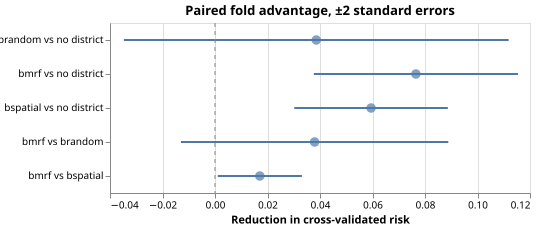

In [6]:
error_bars = alt.Chart(summary).mark_rule(strokeWidth=2, color="#4e79a7").encode(
    y=alt.Y("contrast:N", title=None, sort=None),
    x=alt.X("lo:Q", title="Reduction in cross-validated risk"),
    x2="hi:Q",
).transform_calculate(
    lo="datum.advantage - 2 * datum.se",
    hi="datum.advantage + 2 * datum.se",
)
points = alt.Chart(summary).mark_point(size=90, filled=True, color="#4e79a7").encode(
    y=alt.Y("contrast:N", sort=None), x="advantage:Q",
    tooltip=["contrast", alt.Tooltip("advantage:Q", format=".4f"),
             alt.Tooltip("t:Q", format=".1f")],
)
zero = alt.Chart(pl.DataFrame({"z": [0.0]})).mark_rule(
    strokeDash=[4, 4], color="#888").encode(x="z:Q")

(error_bars + points + zero).properties(
    title="Paired fold advantage, ±2 standard errors", width=420, height=170)

## Paired fold comparison

Adding the district as an unstructured factor reduces risk by 0.039 with a
standard error of 0.037, one standard error from zero, lower in 7 folds of
10. On this evidence `brandom` is not distinguishable from omitting location.

The same district code with the neighbourhood penalty reduces risk by 0.077,
about four standard errors, in 9 folds of 10. The smooth surface over centroids
gives 0.059, also about four standard errors.

The district code is the same predictor in all three specifications. Entered
as an unstructured factor, it cannot be shown to reduce risk; entered with a
neighbourhood penalty or as a surface over centroids, it can.

The mechanism is the 46 single-apartment districts and the median of six.
`brandom` shrinks each district toward the city-wide mean, so a district with
one apartment contributes and receives little. `bmrf` shrinks it toward its
neighbours, and since rent varies smoothly across the city, a neighbouring
district is a closer reference than the city average.


## Non-spatial effects

The district effects are easier to read against the size of the other terms.
`plot_partial_effects` draws the two smooth terms from the `bmrf` fit.


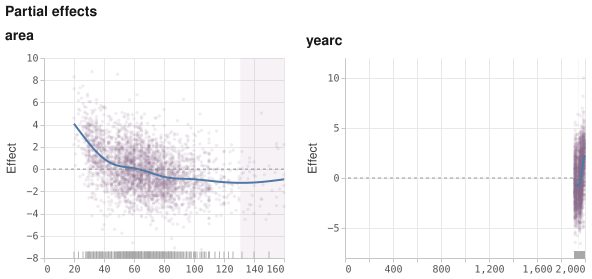

In [7]:
mb.plot.plot_partial_effects(fits["bmrf"], which=["area", "yearc"])

In [8]:
for name, (x, effect) in fits["bmrf"].partial_effects(which=["area", "yearc"]).items():
    order = np.argsort(x)
    print(f"{name:6s} {effect[order][0]:+.2f} at {x[order][0]:.0f} "
          f"-> {effect[order][-1]:+.2f} at {x[order][-1]:.0f} "
          f"(range {effect.max() - effect.min():.2f})")

area   +4.09 at 20 -> -0.92 at 160 (range 5.32)
yearc  -0.62 at 1918 -> +2.27 at 1997 (range 3.06)


Rent per square metre falls with floor area: small flats cost more per square
metre than large ones. The effect is +4.09 for the smallest flats at 20 m² and
−0.92 at 160 m²; its range from largest to smallest value is 5.32, because the
curve reaches its minimum of −1.24 at 132 m² and rises slightly after it.
Construction year runs the other way, from −0.62 for 1918 to +2.27 for 1997,
with a minimum of −0.79 at 1942 and a range of 3.06.

The `bmrf` district effects in the next section span −3.23 to +2.14, a range of
5.37, so location is comparable in size to floor area and larger than
construction year. The most extreme district effects belong to districts with
one or two surveyed apartments.


## Fitted district effects

Each model's district effect is its partial contribution to rent per square
metre, averaged over the apartments in that district and drawn on the city map.


In [9]:
polygons = mb.datasets.munich_rent_polygons()
inverse = {i: d for d, i in position.items()}

effect_frames = []
for label in ("brandom", "bmrf", "bspatial"):
    key = "dx,dy" if label == "bspatial" else "dcode"
    _, effect = fits[label].partial_effects()[key]
    frame = (
        pl.DataFrame({"dcode": data["dcode"], "effect": np.asarray(effect, dtype=float)})
        .group_by("dcode").agg(pl.col("effect").mean())
        .with_columns(pl.col("dcode").replace_strict(inverse).alias("district"))
        .select(["district", "effect"])
        .with_columns(pl.lit(label).alias("model"))
    )
    effect_frames.append(frame)

effects = pl.concat(effect_frames)
display(effects.group_by("model").agg([
    pl.col("effect").std().round(3).alias("sd across districts"),
    pl.col("effect").min().round(2).alias("min"),
    pl.col("effect").max().round(2).alias("max"),
]))

model,sd across districts,min,max
str,f64,f64,f64
"""brandom""",0.337,-1.12,1.03
"""bspatial""",0.43,-3.21,1.05
"""bmrf""",0.459,-3.23,2.14


In [10]:
# One GeoJSON ring per district. mark_geoshape draws a single path per
# feature; encoding the vertices as an area with detail="district" emits
# geometry per row and inflates the figure by two orders of magnitude.
rings = {}

for key, group in polygons.sort("order").group_by("district", maintain_order=True):
    district = key[0] if isinstance(key, tuple) else key
    ring = [[float(x), float(y)] for x, y in zip(group["x"], group["y"])]
    if ring[0] != ring[-1]:
        ring.append(ring[0])
    rings[district] = ring

limit = 1.5


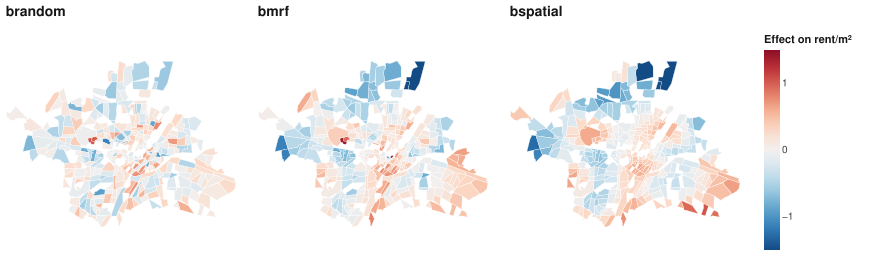

In [11]:
def district_map(label):
    rows = effects.filter(pl.col("model") == label)
    values = dict(zip(rows["district"], rows["effect"]))
    features = [
        {"type": "Feature",
         "properties": {"district": int(d), "effect": float(values[d])},
         "geometry": {"type": "Polygon", "coordinates": [ring]}}
        for d, ring in rings.items() if d in values
    ]
    # A key-type mismatch between the two sources drops every district and
    # draws an empty frame with a legend, which looks like a styling problem
    # rather than a missing join.
    if len(features) != len(values):
        raise ValueError(
            f"{label}: {len(features)} polygons matched {len(values)} effects"
        )
    source = alt.Data(values={"type": "FeatureCollection", "features": features},
                      format=alt.DataFormat(property="features"))
    return alt.Chart(source).mark_geoshape(
        stroke="#ffffff", strokeWidth=0.3
    ).encode(
        color=alt.Color("properties.effect:Q",
                        scale=alt.Scale(scheme="redblue", domain=[-limit, limit],
                                        clamp=True, reverse=True),
                        legend=alt.Legend(title="Effect on rent/m²")),
        tooltip=[alt.Tooltip("properties.district:N", title="district"),
                 alt.Tooltip("properties.effect:Q", format=".2f", title="effect")],
    ).project(type="identity", reflectY=True).properties(
        width=230, height=230, title=label)

alt.hconcat(*(district_map(m) for m in ("brandom", "bmrf", "bspatial")))


`brandom` produces a map with no visible spatial organisation: adjacent
districts take unrelated values, since nothing in the specification connects
them. `bmrf` produces contiguous areas of higher and lower rent while retaining
sharp boundaries. `bspatial` produces the same broad pattern with the
boundaries smoothed away, since a tensor-product spline over centroids cannot
represent a discontinuity between districts a few hundred metres apart.

The spread of the estimates also differs. The standard deviation across
districts is 0.34 for `brandom` and 0.46 for `bmrf`, and the range is wider
under the penalty that shrinks toward neighbours. A district in a high-rent
area is shrunk toward its high-rent neighbours, and a district in a low-rent
area toward its low-rent neighbours, so both keep values further from the city
mean than `brandom`, which shrinks every district toward the city mean, allows.


## `bmrf` compared with `bspatial`

`bmrf` has lower cross-validated risk than `bspatial` by 0.017, about two
standard errors, and is lower in 7 of the 10 folds. That separation is weaker than the
separation between either and no spatial structure.

The two encode different assumptions. The graph holds that rents change at
district boundaries and that bordering districts are similar, and it can keep
two adjacent districts far apart when the data support that. The surface holds
that rent is a smooth function of position, so two apartments 300 metres apart
on opposite sides of a boundary receive nearly the same location effect.

A 2% difference in risk does not distinguish these assumptions. On these
folds, the evidence supports spatial structure over no district term but
does not distinguish the graph from the surface.


## Districts with few observations

The fitted values are anchored by the apartments surveyed. The map assigns a
value to all 336 districts, but 46 of those rest on a single apartment. The
three districts outside the main component of the graph are smoothed only within
their own component: 1212 and 1213 toward each other, and 121 not at all.


districts resting on 1-2 apartments: 79
their effects span [-3.23, 2.14]
effects of districts with 10+ apartments span [-1.14, 0.96]


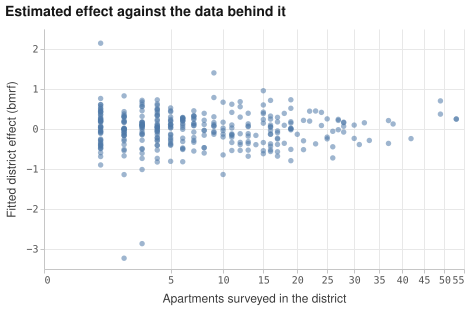

In [12]:
counts = (rent.group_by("district").len()
          .rename({"len": "apartments"}))
support = (effects.filter(pl.col("model") == "bmrf")
           .join(counts, on="district", how="left"))

thin = support.filter(pl.col("apartments") <= 2)
print(f"districts resting on 1-2 apartments: {thin.height}")
print(f"their effects span [{thin['effect'].min():.2f}, {thin['effect'].max():.2f}]")
print(f"effects of districts with 10+ apartments span "
      f"[{support.filter(pl.col('apartments') >= 10)['effect'].min():.2f}, "
      f"{support.filter(pl.col('apartments') >= 10)['effect'].max():.2f}]")

alt.Chart(support).mark_circle(opacity=0.55, color="#4e79a7").encode(
    x=alt.X("apartments:Q", title="Apartments surveyed in the district",
            scale=alt.Scale(type="sqrt")),
    y=alt.Y("effect:Q", title="Fitted district effect (bmrf)"),
    tooltip=["district:N", "apartments:Q", alt.Tooltip("effect:Q", format=".2f")],
).properties(title="Estimated effect against the data behind it",
             width=420, height=240)

The districts with the fewest apartments carry the most extreme fitted effects.
The penalty pulls them toward their neighbours, but a single observation in a
district whose neighbours are also thinly surveyed can remain far from the
centre.

For a rent index the consequence is direct. A tenant in a well-surveyed
district is compared against dozens of local apartments; a tenant in a
single-apartment district is compared against a figure that is largely the
neighbouring districts' average. The displayed decimal precision does not communicate this difference in
estimation uncertainty.


## Conclusions

Location carries information about rent in this survey, and the structure
imposed on the district code determines whether a model can use it. The
neighbourhood graph reduces cross-validated risk by 0.077 against no district
term, about four standard errors of the paired fold difference, and the smooth
surface by 0.059. The same district code as an unstructured factor gives 0.039
with a standard error of 0.037.

Between the graph and the surface the data do not choose. They differ by 0.017,
about two standard errors, with the graph lower in 7 of the 10 folds. Against
no district term the graph gains 0.077 and the surface 0.059, each about four
standard errors. The two encode
different assumptions: the graph allows rents to change at a district boundary
and the surface does not.

The district effects on the map are not all estimated equally well. 46
districts rest on a single surveyed apartment and carry the most extreme fitted
values. District 121 has no neighbours and receives no smoothing, and the pair
1212 and 1213 is smoothed only toward each other.

**Out of scope.** Munich today, new lettings at market rates, and
owner-occupied housing. The survey covers rent-controlled tenancies in 1999.

A factor with many levels is commonly fitted as a random effect. Here that
treatment left the predictor indistinguishable from omitting it. The district
code reduced risk once the spatial relation between districts was supplied, in
this case as the neighbourhood graph included with the survey. Where no such
structure is available, coordinates and a smooth surface recovered most of the
same reduction in risk.
